# 01 · Simulación de datos y fidelidad

Reconstrucción del dataset de Chicco & Jurman (2020) a partir de sus Tablas 1–3 y validación contra el dataset real (UCI).

## Configuración y generación

In [1]:
import os
import sys
from pathlib import Path

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import parametros as P
from src.simulacion import simular, reporte_calibracion
from src.fidelidad import cargar_real, marginales, binarias, dependencia, comparar_rankings, c2st, ranking_mann_whitney

pd.set_option("display.width", 200, "display.max_columns", 30)

real = cargar_real()
sim = simular(random_state=42)

print(RAIZ)
print(real.shape, sim.shape)
print(sim.DEATH_EVENT.value_counts().to_dict())
print((sim.drop(columns="DEATH_EVENT").round(2) == pd.read_csv("data/simulated/hf_simulado_n299_seed42.csv").drop(columns="DEATH_EVENT").round(2)).all().all())

/Users/estebanbejaranocaldas/Documents/maestria_analitica/Trabajo final ML/proyecto_ml_final
(299, 13) (299, 13)
{0: 203, 1: 96}
True


## Calibración de las distribuciones truncadas frente a la Tabla 3

In [2]:
cal = reporte_calibracion()
cal.to_csv("results/calibracion_distribuciones.csv", index=False)
print(cal.to_string(index=False))

 clase                 variable          familia  mediana_obj  mediana_cal  media_obj  media_cal  sd_obj   sd_cal  perdida
     1                      age gamma_desplazada         65.0       64.491      65.22     65.842   13.21   13.235    0.004
     1 creatinine_phosphokinase        lognormal        259.0      200.650     670.20    728.451 1316.58 1280.982    0.005
     1        ejection_fraction    beta_escalada         30.0       30.541      33.47     32.798   12.53   12.773    0.005
     1                platelets            gamma        258.5      251.701     256.38    263.479   98.53   96.892    0.010
     1         serum_creatinine        lognormal          1.3        1.312       1.84      1.825    1.47    1.478    0.000
     1             serum_sodium           normal        135.5      135.480     135.40    135.421    5.00    5.002    0.000
     1                     time    beta_escalada         44.5       46.311      70.89     68.140   62.38   64.033    0.003
     0          

## Fidelidad: marginales, binarias y ranking univariado

In [3]:
m = marginales(real, sim)
b = binarias(real, sim)
rk = comparar_rankings(real, sim)

m.to_csv("results/fidelidad_marginales.csv", index=False)
b.to_csv("results/fidelidad_binarias.csv", index=False)
rk.to_csv("results/fidelidad_ranking_mw.csv")

print(f"KS con p > 0.05: {(m.KS_p > 0.05).sum()} de {len(m)}\n")
print(m.to_string(index=False))
print("\n", b.to_string(index=False))
print("\n", rk.to_string())

KS con p > 0.05: 9 de 14

 clase                 variable  media_paper  media_real  media_sim  mediana_paper  mediana_real  mediana_sim  sd_paper  sd_real   sd_sim  KS_D  KS_p
     1                      age        65.22      65.215     65.833           65.0          65.0       66.000     13.21   13.215   13.566 0.104 0.678
     1 creatinine_phosphokinase       670.20     670.198    639.812          259.0         259.0      203.000   1316.58 1316.581 1048.627 0.219 0.020
     1        ejection_fraction        33.47      33.469     32.042           30.0          30.0       31.000     12.53   12.525   12.109 0.125 0.443
     1                platelets       256.38     256.381    265.604          258.5         258.5      255.305     98.53   98.526   83.914 0.146 0.260
     1         serum_creatinine         1.84       1.836      1.706            1.3           1.3        1.250      1.47    1.469    1.358 0.229 0.013
     1             serum_sodium       135.40     135.375    135.000       

## Distribuciones por clase: real vs. simulado

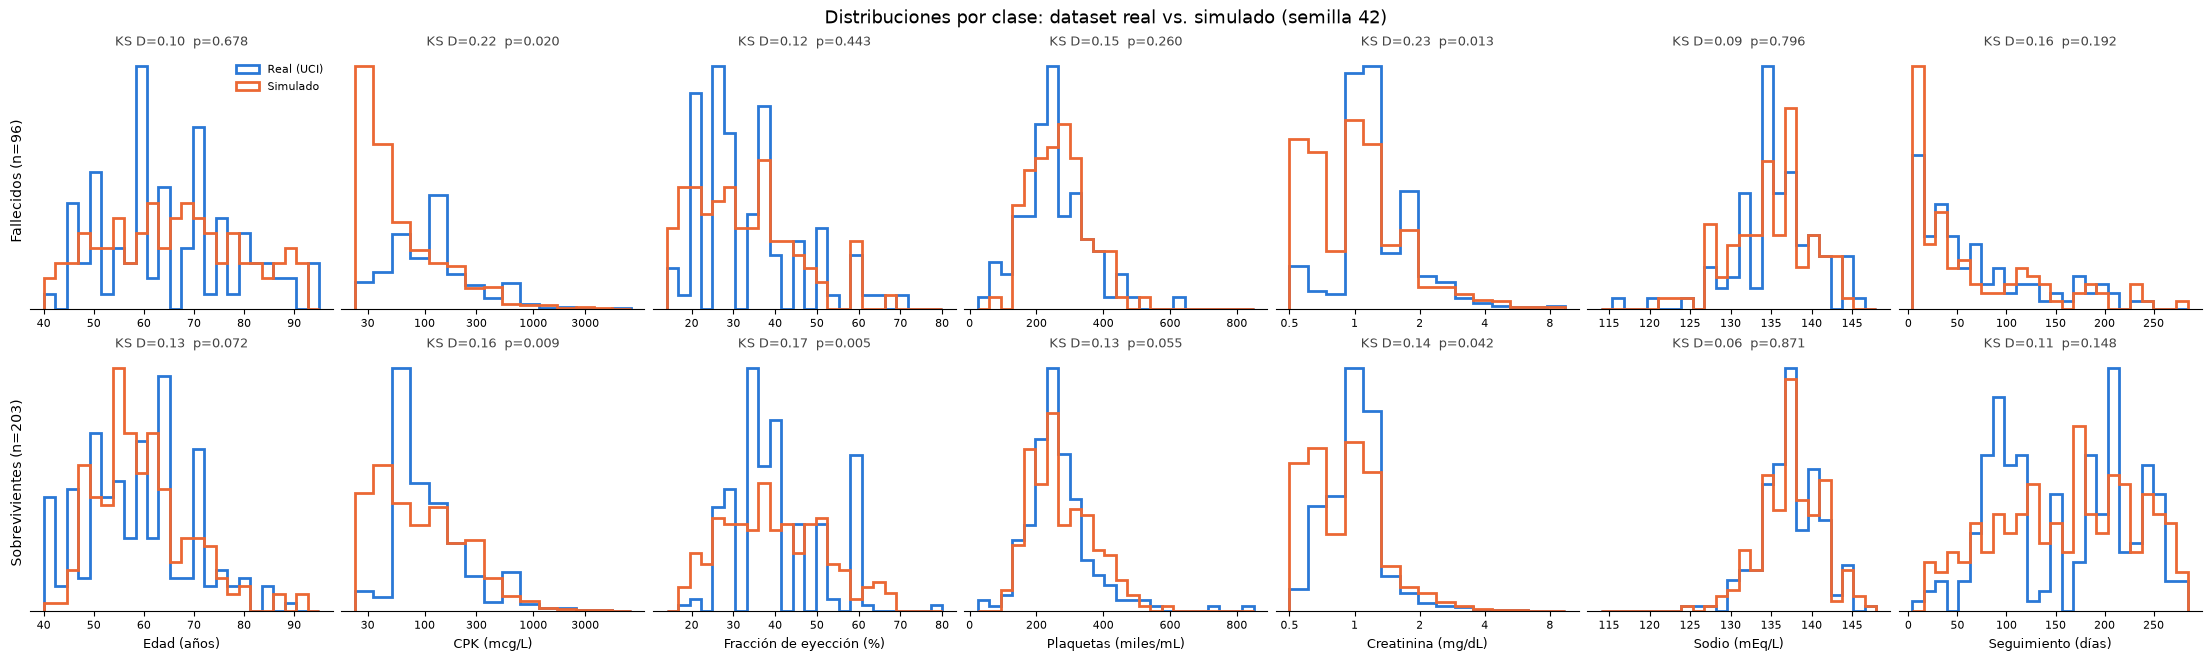

In [4]:
from scipy import stats

COLOR_REAL, COLOR_SIM = "#2a78d6", "#eb6834"
NOMBRES = {"age": "Edad (años)", "creatinine_phosphokinase": "CPK (mcg/L)",
           "ejection_fraction": "Fracción de eyección (%)", "platelets": "Plaquetas (miles/mL)",
           "serum_creatinine": "Creatinina (mg/dL)", "serum_sodium": "Sodio (mEq/L)", "time": "Seguimiento (días)"}
CLASES = {1: "Fallecidos (n=96)", 0: "Sobrevivientes (n=203)"}
variables = list(P.FAMILIA)

fig, ejes = plt.subplots(2, len(variables), figsize=(22, 6.5), constrained_layout=True)
for i, clase in enumerate((1, 0)):
    r, s = real[real.DEATH_EVENT == clase], sim[sim.DEATH_EVENT == clase]
    for j, var in enumerate(variables):
        ax = ejes[i, j]
        esc = 1000 if var == "platelets" else 1
        xr, xs = r[var] / esc, s[var] / esc
        lo, hi = P.RANGOS[var]
        if var in ("creatinine_phosphokinase", "serum_creatinine"):
            bins = np.logspace(np.log10(lo), np.log10(hi), 16)
            ax.set_xscale("log")
            marcas = [0.5, 1, 2, 4, 8] if var == "serum_creatinine" else [30, 100, 300, 1000, 3000]
            ax.set_xticks(marcas)
            ax.set_xticklabels([f"{m:g}" for m in marcas])
            ax.minorticks_off()
        else:
            bins = np.linspace(lo, hi, 25)
        ax.hist(xr, bins=bins, density=True, histtype="step", lw=2, color=COLOR_REAL, label="Real (UCI)")
        ax.hist(xs, bins=bins, density=True, histtype="step", lw=2, color=COLOR_SIM, label="Simulado")
        ks = stats.ks_2samp(xr, xs)
        ax.set_title(f"KS D={ks.statistic:.2f}  p={ks.pvalue:.3f}", fontsize=9, color="#444")
        ax.set_yticks([])
        ax.spines[["top", "right", "left"]].set_visible(False)
        ax.tick_params(labelsize=8)
        if i == 1:
            ax.set_xlabel(NOMBRES[var], fontsize=9)
        if j == 0:
            ax.set_ylabel(CLASES[clase], fontsize=10)
ejes[0, 0].legend(fontsize=8, frameon=False, loc="upper right")
fig.suptitle("Distribuciones por clase: dataset real vs. simulado (semilla 42)", fontsize=13)
fig.savefig("figures/01_marginales_real_vs_sim.png", dpi=150, bbox_inches="tight")
plt.show()

## Poder discriminante univariado (AUC)

In [5]:
from sklearn.metrics import roc_auc_score
from src.fidelidad import PREDICTORAS

def auc_univariado(df, variable):
    auc = roc_auc_score(df["DEATH_EVENT"], df[variable])
    return max(auc, 1 - auc)

tabla_auc = pd.DataFrame({
    "AUC_real": {v: auc_univariado(real, v) for v in PREDICTORAS},
    "AUC_sim": {v: auc_univariado(sim, v) for v in PREDICTORAS},
})
tabla_auc["diferencia"] = tabla_auc["AUC_sim"] - tabla_auc["AUC_real"]
tabla_auc = tabla_auc.sort_values("AUC_real", ascending=False).round(3)
tabla_auc.to_csv("results/auc_univariado_real_vs_sim.csv")
print(tabla_auc.to_string())

                          AUC_real  AUC_sim  diferencia
serum_creatinine             0.728    0.605      -0.123
ejection_fraction            0.676    0.675      -0.001
age                          0.635    0.637       0.003
serum_sodium                 0.629    0.642       0.013
high_blood_pressure          0.541    0.530      -0.010
anaemia                      0.535    0.561       0.026
platelets                    0.529    0.518      -0.011
creatinine_phosphokinase     0.515    0.533       0.019
smoking                      0.506    0.556       0.050
sex                          0.502    0.536       0.034
diabetes                     0.501    0.523       0.022


## Robustez frente a la semilla del generador

In [6]:
auc_creat = [auc_univariado(simular(random_state=s), "serum_creatinine") for s in range(50)]
puestos = [list(ranking_mann_whitney(simular(random_state=s)).index).index("serum_creatinine") + 1
           for s in range(200)]

print(f"AUC univariado creatinina, 50 semillas: media {np.mean(auc_creat):.3f} "
      f"(rango {min(auc_creat):.3f}–{max(auc_creat):.3f}); dato real {auc_univariado(real, 'serum_creatinine'):.3f}")
print("Puesto de la creatinina en el ranking Mann-Whitney, 200 semillas:")
print(pd.Series(puestos).value_counts().sort_index().to_string())

AUC univariado creatinina, 50 semillas: media 0.630 (rango 0.544–0.730); dato real 0.728
Puesto de la creatinina en el ranking Mann-Whitney, 200 semillas:
1    24
2    62
3    48
4    38
5    17
6     6
7     1
8     2
9     2


## Dependencia entre variables y C2ST

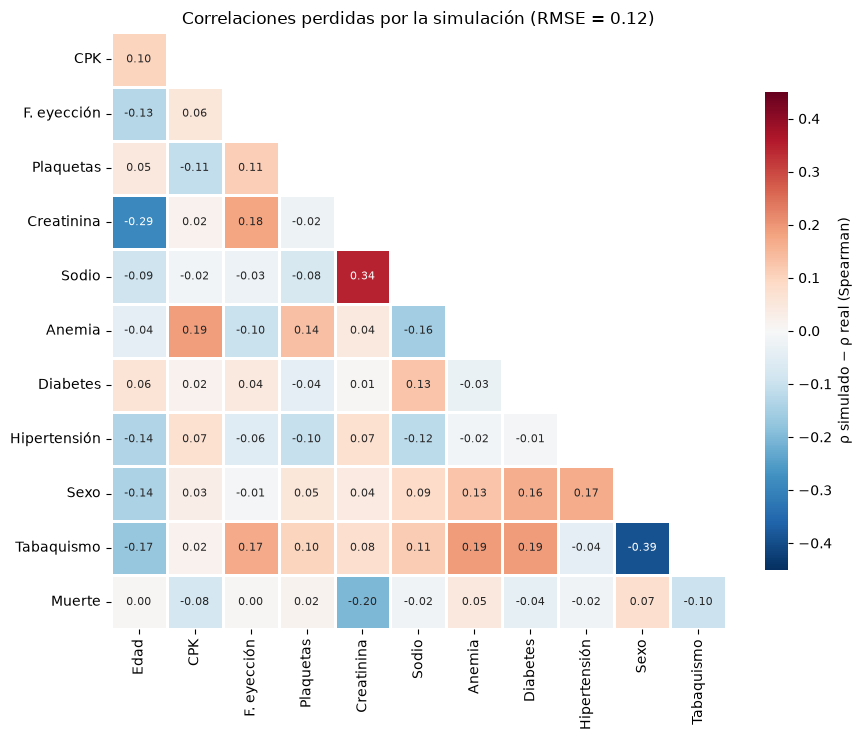

C2ST: AUC = 0.776 ± 0.023


In [7]:
dif, resumen_dep = dependencia(real, sim)

CORTOS = {"age": "Edad", "creatinine_phosphokinase": "CPK", "ejection_fraction": "F. eyección",
          "platelets": "Plaquetas", "serum_creatinine": "Creatinina", "serum_sodium": "Sodio",
          "anaemia": "Anemia", "diabetes": "Diabetes", "high_blood_pressure": "Hipertensión",
          "sex": "Sexo", "smoking": "Tabaquismo", "DEATH_EVENT": "Muerte"}
dif_c = dif.rename(index=CORTOS, columns=CORTOS).iloc[1:, :-1]
mascara = np.triu(np.ones_like(dif_c, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(dif_c, mask=mascara, cmap="RdBu_r", center=0, vmin=-0.45, vmax=0.45,
            annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=2, linecolor="white",
            cbar_kws={"label": "ρ simulado − ρ real (Spearman)", "shrink": 0.8}, ax=ax)
ax.set_title(f"Correlaciones perdidas por la simulación (RMSE = {resumen_dep['rmse']:.2f})", fontsize=12)
fig.tight_layout()
fig.savefig("figures/01_dif_spearman.png", dpi=150, bbox_inches="tight")
plt.show()

resultado_c2st = c2st(real, sim)
print(f"C2ST: AUC = {resultado_c2st['auc_media']:.3f} ± {resultado_c2st['auc_sd']:.3f}")

## C2ST: efecto de los artefactos del dataset real

In [8]:
imputadas = ((real.creatinine_phosphokinase == 582) | (real.platelets == 263358.03)
             | real.serum_creatinine.isin([1.18, 1.83]))
real_limpio = real[~imputadas]
sim_mismo_n = sim.sample(len(real_limpio), random_state=0)
sim_ef5 = sim_mismo_n.assign(ejection_fraction=(5 * np.round(sim_mismo_n.ejection_fraction / 5)).astype(int))

idx = np.random.default_rng(0).permutation(len(real))
escenarios = {
    "Base": c2st(real, sim)["auc_media"],
    "Sin filas imputadas del dato real": c2st(real_limpio, sim_mismo_n)["auc_media"],
    "Además, fracción de eyección en múltiplos de 5": c2st(real_limpio, sim_ef5)["auc_media"],
    "Piso: real vs. real (dos mitades)": c2st(real.iloc[idx[:150]], real.iloc[idx[150:]])["auc_media"],
}
print(f"Filas con valores imputados en el dato real: {imputadas.sum()}\n")
print(pd.Series(escenarios, name="AUC C2ST").round(3).to_string())

Filas con valores imputados en el dato real: 62

Base                                              0.776
Sin filas imputadas del dato real                 0.759
Además, fracción de eyección en múltiplos de 5    0.709
Piso: real vs. real (dos mitades)                 0.510
